[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/07-llms-and-genai/notebooks/01-how-llms-work.ipynb)

# 01 - How LLMs work: next tokens, sampling and the context window

**Goal:** look inside a real (tiny) LLM and watch it predict the next token, see how **temperature** and **top-p** change its choices, and measure a **context window**.

We use `HuggingFaceTB/SmolLM2-135M-Instruct` — a 135-million-parameter model that runs on any CPU. Big chat models work the same way, with far more parameters. No API keys. First run downloads about 270 MB.

## Setup
Install anything missing and load the model and tokenizer. `model.eval()` switches the model to inference (use) mode.

In [1]:
import importlib.util, subprocess, sys
# Install a package only if it is missing (Colab already has most of these).
def ensure(pkg, module=None):
    if importlib.util.find_spec(module or pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
ensure("transformers"); ensure("torch")

import torch, numpy as np, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
torch.manual_seed(0)

NAME = "HuggingFaceTB/SmolLM2-135M-Instruct"
tok = AutoTokenizer.from_pretrained(NAME)
# dtype=torch.float32: the weights are stored in bfloat16, which is very slow on most CPUs
model = AutoModelForCausalLM.from_pretrained(NAME, dtype=torch.float32).eval()
print(f"Loaded {NAME}: {sum(p.numel() for p in model.parameters())/1e6:.0f}M parameters, vocab {tok.vocab_size:,}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights:  42%|████▏     | 113/272 [00:00<00:00, 1124.36it/s]

Loading weights:  96%|█████████▌| 261/272 [00:00<00:00, 1324.92it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1304.28it/s]

Loaded HuggingFaceTB/SmolLM2-135M-Instruct: 135M parameters, vocab 49,152


## 1. Next-token probabilities

The model outputs one **logit** (raw score) per vocabulary token for the position after the last token. **Softmax** turns logits into probabilities. We print the 10 most likely next tokens.

In [2]:
def next_token_probs(text):
    ids = tok(text, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        logits = model(input_ids=ids).logits[0, -1]     # scores for the NEXT token
    return logits, torch.softmax(logits, dim=-1)

prompt = "The capital of France is"
logits, probs = next_token_probs(prompt)
top = torch.topk(probs, 10)
for p, i in zip(top.values, top.indices):
    print(f"{tok.decode(int(i))!r:<14} {float(p):6.1%}")
print("Sum of ALL probabilities:", round(float(probs.sum()), 4))

' Paris'        46.9%
' the'          26.6%
' located'       8.3%
' called'        1.8%
' Le'            1.5%
' a'             0.8%
' known'         0.6%
' La'            0.6%
' situated'      0.5%
' Mon'           0.5%
Sum of ALL probabilities: 1.0


Draw it as a bar chart. The model is ranking possible continuations, not looking up a fact.

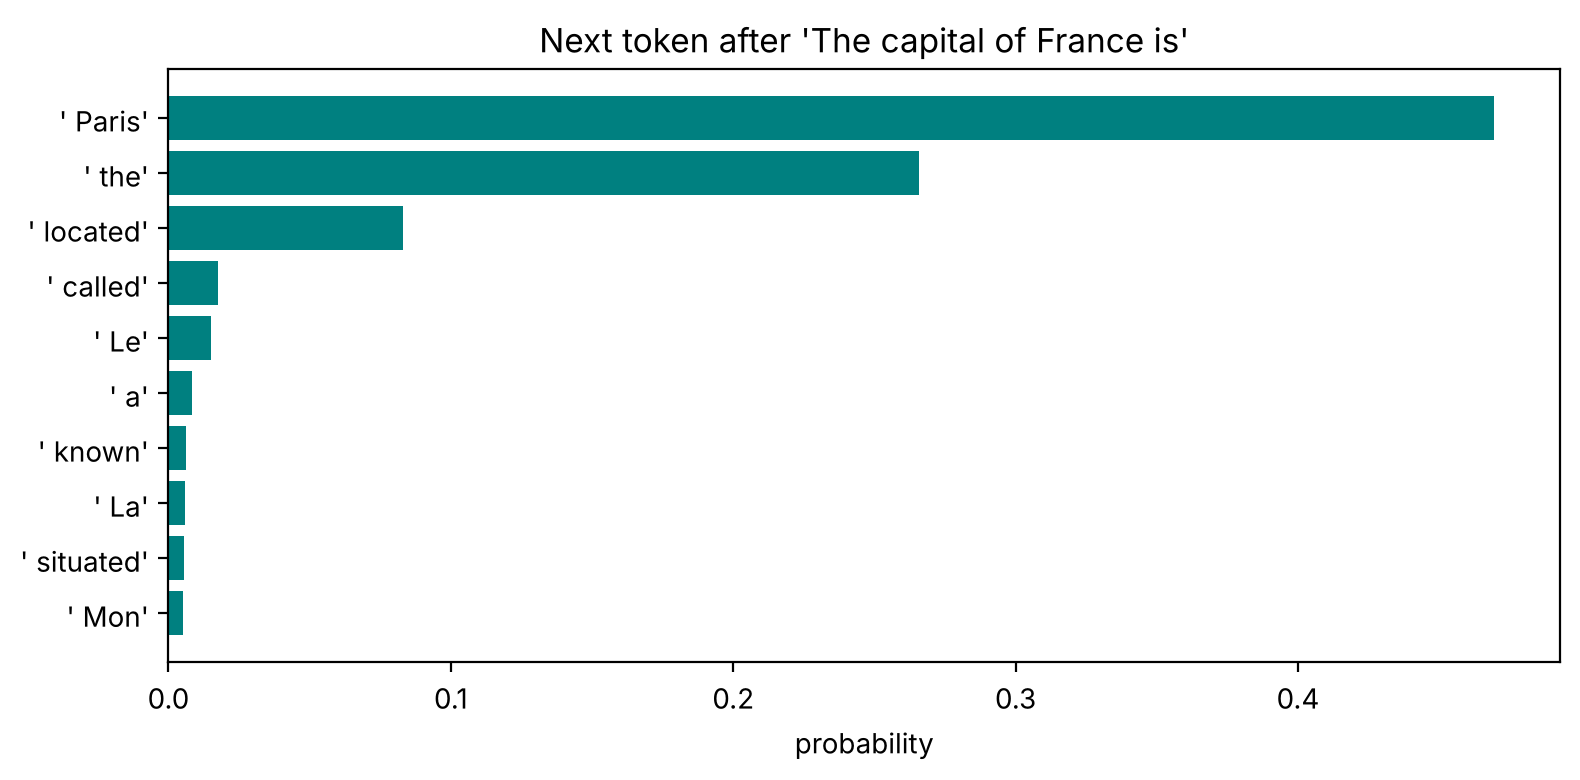

In [3]:
labels = [repr(tok.decode(int(i))) for i in top.indices]
plt.figure(figsize=(8, 4))
plt.barh(labels[::-1], top.values.numpy()[::-1], color="teal")
plt.xlabel("probability"); plt.title(f"Next token after {prompt!r}")
plt.tight_layout(); plt.show()

## 2. The generation loop, by hand

**Autoregressive** generation: predict → pick → append → repeat. Here we always pick the top token (**greedy decoding**) and print the probability of each choice. Watch how confident the model is at each step.

In [4]:
text = prompt
for step in range(10):
    _, p = next_token_probs(text)
    best = int(torch.argmax(p))
    text += tok.decode(best)
    print(f"step {step+1:>2}: picked {tok.decode(best)!r:<12} with p={float(p[best]):.2f}")
print("\nResult:", text)

step  1: picked ' Paris'     with p=0.47
step  2: picked '.'          with p=0.54
step  3: picked ' Paris'     with p=0.39


step  4: picked ' is'        with p=0.89
step  5: picked ' the'       with p=0.35


step  6: picked ' largest'   with p=0.33
step  7: picked ' city'      with p=0.75


step  8: picked ' in'        with p=0.93
step  9: picked ' France'    with p=0.70


step 10: picked ' and'       with p=0.63

Result: The capital of France is Paris. Paris is the largest city in France and


## 3. Temperature

**Temperature** divides every logit before softmax. Low temperature sharpens the distribution (the favourite wins almost always); high temperature flattens it (surprising tokens get a real chance).

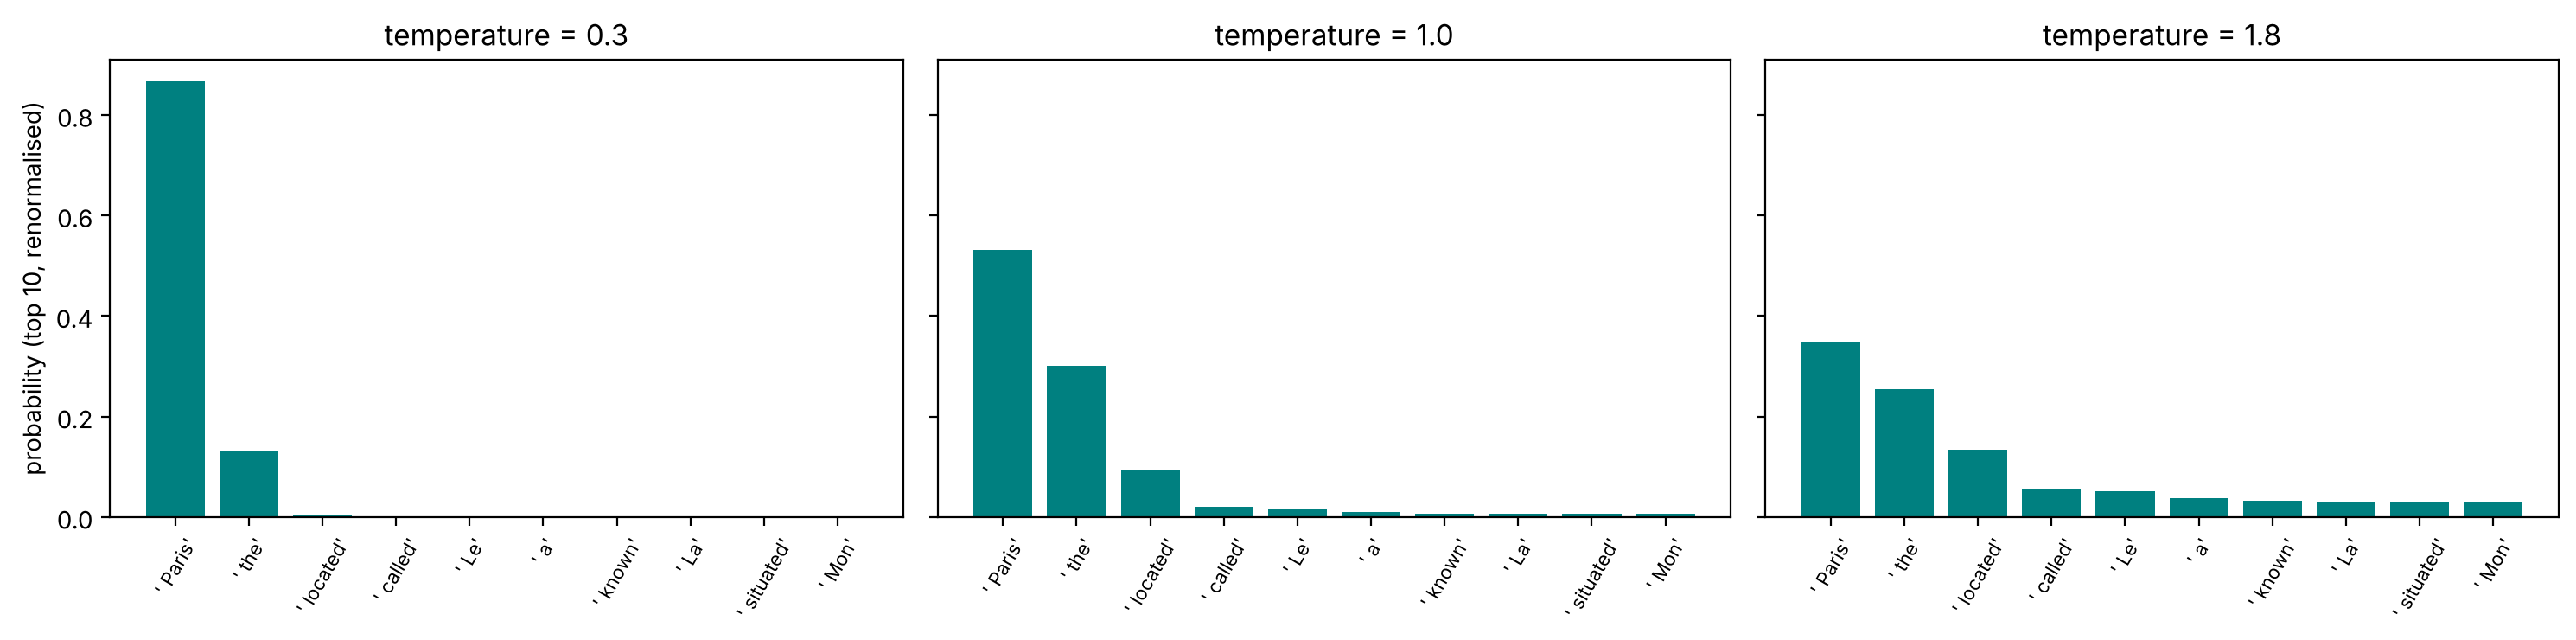

In [5]:
top_logits = logits[top.indices]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, T in zip(axes, [0.3, 1.0, 1.8]):
    p = torch.softmax(top_logits / T, dim=-1).numpy()
    ax.bar(range(10), p, color="teal"); ax.set_title(f"temperature = {T}")
    ax.set_xticks(range(10), labels=labels, rotation=60, fontsize=8)
axes[0].set_ylabel("probability (top 10, renormalised)")
plt.tight_layout(); plt.show()

## 4. Top-p (nucleus) sampling

**Top-p** keeps the smallest group of most-likely tokens whose probabilities add up to at least p, throws the rest away, and renormalises. Let's write it and see which tokens survive p = 0.9 and p = 0.5.

In [6]:
def top_p_keep(probs, p):
    sorted_p, sorted_idx = torch.sort(probs, descending=True)
    cumulative = torch.cumsum(sorted_p, dim=0)
    n_keep = int((cumulative < p).sum()) + 1              # tokens needed to reach p
    return sorted_idx[:n_keep]

for p in [0.5, 0.9]:
    keep = top_p_keep(probs, p)
    print(f"top-p={p}: keeps {len(keep)} tokens ->", [tok.decode(int(i)) for i in keep][:15])

top-p=0.5: keeps 2 tokens -> [' Paris', ' the']
top-p=0.9: keeps 16 tokens -> [' Paris', ' the', ' located', ' called', ' Le', ' a', ' known', ' La', ' situated', ' Mon', ' St', ' not', ' Saint', ' City', ' Ch']


## 5. Sampling with `generate()`

Now let Hugging Face do it. `do_sample=True` turns on random sampling; we try three temperatures, three runs each (different random **seeds** — starting points for the random number generator). Low temperature stays close to the most likely wording; high temperature wanders further (and gets weirder). Even at low temperature, runs can differ when the first few tokens have similar probabilities.

In [7]:
chat = [{"role": "user", "content": "Give me a name for a cat cafe."}]
inputs = tok.apply_chat_template(chat, add_generation_prompt=True, return_tensors="pt", return_dict=True)
for T in [0.2, 0.8, 1.5]:
    print(f"--- temperature {T}")
    for seed in range(3):
        torch.manual_seed(seed)
        out = model.generate(**inputs, max_new_tokens=15, do_sample=True, temperature=T, top_p=0.95)
        print("  ", tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip())

--- temperature 0.2


   I'm sorry for the confusion, but as a chatbot, I don


   A cat cafe is a delightful establishment where cats can enjoy a variety of


   A cat cafe is a delightful place where cats can relax and socialize with
--- temperature 0.8


   The cat cafe, a charming little institution that's been serving up fresh


   A cat cafe is a fantastic idea! I can create a name that


   To create a cat cafe, let's start with a name that's
--- temperature 1.5


   The cat cafe, just known as Akakar, is not quite


   Let me think for a moment. My name is Shudder and my


   To create an enticing name for a cat cafe, I would suggest the


## 6. The context window

The **context window** is the most tokens the model can handle at once (input + output). For SmolLM2 it is in the model config. Frontier API models allow far more — check each provider's model page.

In [8]:
print("max_position_embeddings (context window):", model.config.max_position_embeddings)
print("tokenizer.model_max_length:", tok.model_max_length)

max_position_embeddings (context window): 8192
tokenizer.model_max_length: 8192


In a chat app the **whole history is re-sent every turn**, so input tokens grow with each message. Let's simulate a 12-turn conversation and count tokens per request, then see when it would overflow a small 1,024-token window.

In [9]:
history = [{"role": "system", "content": "You are a helpful travel assistant for trips in India."}]
window = 1024
rows = []
for turn in range(1, 13):
    history.append({"role": "user", "content": f"Question {turn}: suggest three things to do in city number {turn}, with timings and prices."})
    history.append({"role": "assistant", "content": "Here are three ideas: a morning heritage walk (7-9am), a food market visit in the afternoon, and an evening boat ride. Prices vary; check locally. " * 2})
    n = len(tok.apply_chat_template(history, tokenize=True, return_dict=False))   # list of token IDs
    rows.append((turn, n))
    flag = "  <-- over the window, must trim or summarise!" if n > window else ""
    print(f"turn {turn:>2}: {n:>5} tokens sent{flag}")

turn  1:   119 tokens sent
turn  2:   222 tokens sent
turn  3:   325 tokens sent
turn  4:   428 tokens sent
turn  5:   531 tokens sent
turn  6:   634 tokens sent
turn  7:   737 tokens sent
turn  8:   840 tokens sent
turn  9:   943 tokens sent
turn 10:  1048 tokens sent  <-- over the window, must trim or summarise!
turn 11:  1153 tokens sent  <-- over the window, must trim or summarise!
turn 12:  1258 tokens sent  <-- over the window, must trim or summarise!


A simple fix is a **sliding window**: keep the system prompt and only the most recent messages that fit. (Module 08 covers smarter options like summarising old turns.)

In [10]:
def trim_history(history, max_tokens):
    system, rest = history[:1], history[1:]
    while rest and len(tok.apply_chat_template(system + rest, tokenize=True, return_dict=False)) > max_tokens:
        rest = rest[2:]                       # drop the oldest user+assistant pair
    return system + rest

trimmed = trim_history(history, window)
print("messages before:", len(history), " after:", len(trimmed),
      " tokens after:", len(tok.apply_chat_template(trimmed, tokenize=True, return_dict=False)))

messages before: 25  after: 19  tokens after: 949


## 7. Why chat templates matter (base vs instruct behaviour)

Instruct models were trained with special markers around each role. Without them the model behaves more like a **base model** and continues the text. Below, the raw text looks like the start of a quiz page, so the model continues the quiz with more questions instead of answering. With the chat template, the same model answers.

Notice also that SmolLM2's template inserts a default system prompt when we don't give one.

In [11]:
question = "What is the capital of France?"
raw = tok("Geography quiz:\n1. " + question + "\n2.", return_tensors="pt")
out = model.generate(**raw, max_new_tokens=25, do_sample=False)
print("RAW (no template):", repr(tok.decode(out[0][raw["input_ids"].shape[1]:], skip_special_tokens=True)))

templ = tok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True,
                                return_tensors="pt", return_dict=True)
out = model.generate(**templ, max_new_tokens=25, do_sample=False)
print("WITH TEMPLATE:   ", repr(tok.decode(out[0][templ["input_ids"].shape[1]:], skip_special_tokens=True)))
print("\nThe template text the model actually saw:\n" + tok.apply_chat_template([{"role": "user", "content": question}], add_generation_prompt=True, tokenize=False))

RAW (no template): ' What is the name of the largest city in France?\n3. What is the name of the largest river in France?'


WITH TEMPLATE:    'The capital of France is Paris.'

The template text the model actually saw:
<|im_start|>system
You are a helpful AI assistant named SmolLM, trained by Hugging Face<|im_end|>
<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant



## Try it yourself
1. Change `prompt` to `"The best programming language for beginners is"`. How spread out are the probabilities?
2. In section 5, set `temperature=3.0`. What happens to the text?
3. Change `window` to 4096. At which turn would the conversation overflow now?
4. Pick a prompt where the top token has less than 20% probability. What does that tell you about how "sure" the model is?